# Filtered back projection (SPECT)

Filtered back projection (FBP) is the classic analytic reconstruction: for decades the standard on SPECT scanners, and still the reference that iterative methods are compared with. In PyTomography it is one algorithm, `FilteredBackProjection`, for every geometry that supports it: it takes the projections and a system matrix, and the system matrix does the work in its own geometry. This tutorial reconstructs a SPECT scan of a Lu-177 NEMA phantom from a Siemens Symbia with it, corrects the result for attenuation with Chang's method, and compares it with OSEM on the same projections. The [CT version](t_fbp_ct.ipynb) does the same for a helical CT scan.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-NEMA-SymT2")

SPECT/Lu177-NEMA-SymT2: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import FilteredBackProjection, OSEM

In [3]:
# Memory: this tutorial needs about 5 GB of RAM, most of it PyTorch and CUDA themselves. Each reconstruction
# prints its estimate before it runs (estimate_memory). RAM_GB changes nothing here: SPECT reconstructions this size
# never need to split their work.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The idea

Each view of a SPECT scan records, for every pixel, the counts from along the line its collimator hole looks down. Back projection spreads each view back along those lines and adds up the views. On its own it gives a blurred image: every point is smeared out as $1/r$. Multiplying the spectrum of each projection by the ramp $|f|$ before back projecting removes that blur exactly, but it also amplifies noise, which is strongest at high spatial frequencies. So the ramp is multiplied by a window $W(f)$ that falls to zero at high frequencies. `filter` sets the window: a name (`'ram-lak'`, no window; `'hann'`, `'hamming'`, `'shepp-logan'`, `'cosine'`), a window with a cut-off such as `HannFilter(cutoff=0.5)` from `pytomography.utils`, or any function of the spatial frequency in cycles per mm.

FBP only uses the geometry of the system matrix: its transforms (attenuation, collimator blurring) are not applied, so the effects they model have to be corrected some other way, or not at all.

## 2. The scan

The projections are 96 views over 360° from the two heads of the camera, 15 s each, in the 208 keV photopeak window of Lu-177. The two windows either side of it give a triple-energy-window (TEW) estimate of the scatter in the photopeak, which FBP cannot model, so it is subtracted from the projections first. The system matrix is built with attenuation and collimator blurring for the OSEM reconstruction of section 4; FBP uses only its geometry.

In [4]:
path = DATA / 'SPECT' / 'Lu177-NEMA-SymT2'
file_NM = str(path / 'projection_data.dcm')
files_CT = sorted(str(f) for f in (path / 'CT').glob('*'))
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
photopeak = projections[0]  # the 208 keV window
scatter = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2)
photon_keV = proj_meta.energy_windows[0].photon_keV
att_transform = SPECTAttenuationTransform(io.attenuation_map(files_CT, object_meta, energy_keV=photon_keV))
psf_transform = SPECTPSFTransform(io.SPECT.collimator_psf('SY-ME', photon_keV, intrinsic_fwhm_mm=3.8))
system_matrix = SPECTSystemMatrix(obj2obj_transforms=[att_transform, psf_transform], proj2proj_transforms=[],
                                  object_meta=object_meta, proj_meta=proj_meta)
print(f"{proj_meta.num_projections} views of {photopeak.shape[1]} x {photopeak.shape[2]} pixels of {object_meta.dr[0]:.2f} mm; "
      f"{photopeak.sum():.3g} counts, of which TEW estimates {scatter.sum() / photopeak.sum():.0%} are scatter")
print(f"counts in a pixel of one view: {photopeak[photopeak > 0.1 * photopeak.max()].median():.0f} over the phantom, {photopeak.max():.0f} at most")

96 views of 128 x 128 pixels of 4.80 mm; 5.78e+06 counts, of which TEW estimates 31% are scatter
counts in a pixel of one view: 26 over the phantom, 90 at most


## 3. Filtered back projection

SPECT projections hold few counts, about 25 in a pixel of one view, so their noise is large: one over the square root of the counts, 20% in each pixel. It is spread evenly over all spatial frequencies, while the object's own signal falls off at high frequencies, where the ramp amplifies the noise most. A SPECT window therefore cuts off well below the Nyquist frequency of the projection pixels, 0.104 cycles per mm for 4.8 mm pixels. The Butterworth window, $W(f) = 1/\sqrt{1 + (f/f_c)^{2n}}$, is the usual choice; here with a cut-off $f_c$ of 0.05 cycles per mm and order $n = 5$. (A CT scan holds far more photons per ray, so its windows reach the Nyquist frequency: see the [CT version](t_fbp_ct.ipynb).)

In [5]:
butterworth = lambda f: 1 / torch.sqrt(1 + (f / 0.05) ** 10)  # cut-off 0.05 cycles/mm, order 5
fbp = FilteredBackProjection(photopeak - scatter, system_matrix, filter=butterworth)
print(fbp.estimate_memory())
t0 = time.time()
recon_fbp = fbp()
print(f"FBP: {time.time() - t0:.1f} s")

Filtered back projection (SPECTSystemMatrix)
Peak ~ 4.0 GB RAM, 0.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.1 GB GPU (projections 0.01 GPU, image and its support 0.03 GPU, rotation grids of every view 0.03 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: spread and rotated 0.1 GPU)
  Python, CUDA, allocator: 3.8 GB RAM, 0.1 GB GPU (Python, PyTorch and CUDA 3.7 RAM, PyTorch's GPU cache (rounded and kept blocks) 0.1 GPU, memory the allocators keep (Windows) 0.1 RAM)
(plus whatever else your script keeps)


FBP: 0.3 s


Without attenuation correction, activity deep in the phantom reads low: the photons from the centre cross about 100 mm of water to reach the camera, and at 208 keV three in four of them are absorbed or scattered on the way. Chang's first-order correction divides each voxel by the fraction of its photons that would escape, averaged over all the views. That average comes from the CT: a system matrix with only the attenuation transform back projects a projection of ones into $\sum_\theta e^{-\int \mu}$ for each voxel, so dividing the number of views by it gives the correction.

In [6]:
attenuation_only = SPECTSystemMatrix(obj2obj_transforms=[att_transform], proj2proj_transforms=[],
                                     object_meta=object_meta, proj_meta=proj_meta)
chang = proj_meta.num_projections / attenuation_only.compute_normalization_factor()
recon_fbp_chang = recon_fbp * chang

## 4. OSEM for comparison

OSEM models what FBP leaves out: attenuation and collimator blurring in the system matrix, and the scatter estimate in the likelihood, instead of subtracting it. Four iterations of eight subsets, as in the [DICOM introduction](t_dicomdata.ipynb):

In [7]:
likelihood = PoissonLogLikelihood(system_matrix, photopeak, scatter)
osem = OSEM(likelihood)
print(osem.estimate_memory(n_subsets=8))
t0 = time.time()
recon_osem = osem(n_iters=4, n_subsets=8)
print(f"OSEM 4 x 8: {time.time() - t0:.1f} s")

OSEM (SPECTSystemMatrix): 8 subsets, memory budget 25 GB
Peak ~ 4.4 GB RAM, 0.5 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, projections (the data) 0.04 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.8 GB RAM, 0.1 GB GPU (Python, PyTorch and CUDA 3.7 RAM, PyTorch's GPU cache (rounded and kept blocks) 0.1 GPU, memory the allocators keep (Windows) 0.1 RAM)
To use less: 4 subsets ~ 4.3 GB RAM, 0.5 GB GPU
(plus whatever else your script keeps)


OSEM 4 x 8: 0.9 s


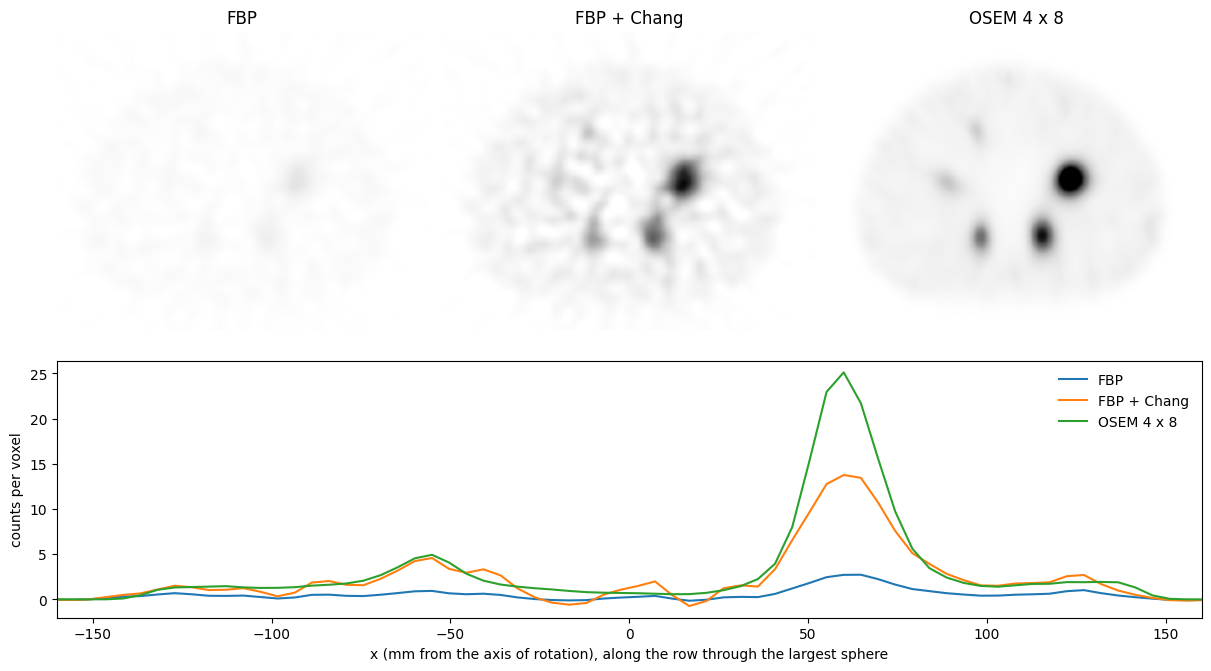

FBP          background: mean  0.37 counts per voxel, voxel-to-voxel variation  48%
FBP + Chang  background: mean  1.51 counts per voxel, voxel-to-voxel variation  48%
OSEM 4 x 8   background: mean  1.50 counts per voxel, voxel-to-voxel variation  12%


In [8]:
z = 61  # the slice through the centres of the spheres
y = 68  # a row through the largest sphere
background = (slice(42, 56), slice(62, 76), slice(70, 80))  # water beside the lung insert, above the spheres
images = [('FBP', recon_fbp), ('FBP + Chang', recon_fbp_chang), ('OSEM 4 x 8', recon_osem)]
vmax = 0.6 * float(recon_osem[:, :, z].max())  # one scale for all three
crop = (slice(30, 102), slice(40, 98))
fig = plt.figure(figsize=(12, 6.6), constrained_layout=True)
grid = fig.add_gridspec(2, 3, height_ratios=[1, 0.75])
for i, (name, image) in enumerate(images):
    ax = fig.add_subplot(grid[0, i])
    ax.imshow(image[crop[0], crop[1], z].cpu().T, cmap='Greys', vmin=0, vmax=vmax, interpolation='gaussian')  # anterior up
    ax.set_title(name)
    ax.axis('off')
ax = fig.add_subplot(grid[1, :])
x_mm = (np.arange(object_meta.shape[0]) - (object_meta.shape[0] - 1) / 2) * object_meta.dr[0]
for name, image in images:
    ax.plot(x_mm, image[:, y, z].cpu(), label=name)
ax.set(xlim=(-160, 160), xlabel='x (mm from the axis of rotation), along the row through the largest sphere', ylabel='counts per voxel')
ax.legend(frameon=False)
plt.show()
for name, image in images:
    b = image[background]
    print(f"{name:12s} background: mean {float(b.mean()):5.2f} counts per voxel, voxel-to-voxel variation {float(b.std() / b.mean()):4.0%}")

FBP alone reads about a quarter of the activity in the background: that is attenuation. With Chang's correction the mean of the background agrees with OSEM's to about 1%, which is all a first-order correction can do in a uniform region. FBP's image stays four times as noisy, and its spheres are lower and wider: OSEM models the collimator's blurring and the Poisson statistics of the counts, so it recovers more of each sphere's activity from the same projections. That is why quantitative SPECT uses OSEM, or the other iterative algorithms compared in the [algorithms tutorial on measured data](t_algorithms_measured.ipynb).

## Save the images

`io.save_dicom` writes each reconstruction as a DICOM nuclear medicine (NM) file, in counts, in its place in the patient (`object_meta.affine`). `reference=file_NM` gives them the patient and study of the projections, so DICOM viewers show them with the scan's CT.

In [9]:
for name, image, description in [('fbp', recon_fbp, 'FBP, Butterworth'), ('fbp_chang', recon_fbp_chang, 'FBP, Butterworth, Chang'),
                                 ('osem', recon_osem, 'OSEM 4x8')]:
    io.save_dicom(image, OUTPUT / 't_fbp_spect' / name, object_meta, reference=file_NM, units='counts',
                  series_description=description, overwrite=True)

## Next steps

- Try other windows: a lower Butterworth cut-off, or `HannFilter(cutoff=0.5)` from `pytomography.utils`, and watch the noise of the background and the height of the spheres.
- The [CT version](t_fbp_ct.ipynb) reconstructs a helical CT scan with the same class, and compares its windows and memory settings.
- The [algorithms tutorial on measured data](t_algorithms_measured.ipynb) compares the iterative algorithms on this phantom, sphere by sphere.